# 04 – Dropout model: baselines, model and evaluation

Goal: predict which students will drop out, so a teacher can help them early.
Input: `data/clean/features.csv` (one row per student, from notebook 03). Output: `outputs/at_risk_students.csv` for Part 2.

## Approach
- 80/20 train/test split, stratified so both parts keep the 25% dropout share (`random_state=42`).
- Two baselines to beat: always predict "stays", and a simple rule ("inactive for more than 30 days").
- Two models: logistic regression and random forest. Missing values are filled with the median of the training students only, inside a `Pipeline`, so no test data leaks in. `class_weight="balanced"` gives the rarer dropout class more weight.
- Evaluation: precision, recall and F1 on the test set, a confusion matrix, and 5-fold cross-validation over all 500 students (the test set has only 100 students, 25 of them dropouts, so one split is noisy).

## Decisions
| Decision | Choice | Why |
|---|---|---|
| Leakage | `refund_requested` is not a feature | Almost perfectly tied to dropout (91% vs 5%) and likely only known after the student leaves; shown in the leakage check below |
| Main metric | Recall, with precision and F1 reported next to it | A missed dropout is a student we could have helped and lost; a false alarm costs one extra friendly message |
| Accuracy | Not used | "Always stays" already scores 75% and catches nobody |
| Threshold | 0.4 instead of 0.5 | In cross-validation it catches more dropouts (recall 0.83 vs 0.77) for some loss of precision. On the 100-student test set the recall is the same (0.80, see the check below), so the gain is small and noisy. A recall-first policy choice; would be raised if the team had little follow-up capacity |

In [1]:
#load features and imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("../data/clean/features.csv")
df.shape

(500, 17)

In [2]:
#choose features and split (refund_requested is NOT a feature)
NUM = ["n_attempts", "n_lessons", "mean_score", "min_score", "last_score", "mean_time",
       "days_since_last", "active_span_days", "n_explanations", "days_since_signup"]
CAT = ["age_group", "device", "country"]
X = pd.get_dummies(df[NUM + CAT], columns=CAT)
y = df.dropped
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("train:", Xtr.shape, "test:", Xte.shape)
print("dropout share, train / test:", round(ytr.mean(), 2), round(yte.mean(), 2))

train: (400, 24) test: (100, 24)
dropout share, train / test: 0.25 0.25


In [3]:
#baselines and models, evaluated on the test set
def score(name, y_true, pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average="binary", zero_division=0)
    return {"model": name, "precision": round(p, 2), "recall": round(r, 2), "f1": round(f, 2)}

results = []
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
results.append(score("baseline: always 'stays'", yte, dummy.predict(Xte)))
rule = (Xte.days_since_last > 30).astype(int)
results.append(score("rule: inactive > 30 days", yte, rule))
print("the 30-day rule flags", round(rule.mean() * 100), "% of test students")

lr = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()),
               ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(Xtr, ytr)
rf = Pipeline([("imp", SimpleImputer(strategy="median")),
               ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                            class_weight="balanced", random_state=42))]).fit(Xtr, ytr)
results.append(score("logistic regression", yte, lr.predict(Xte)))
results.append(score("random forest", yte, rf.predict(Xte)))
pd.DataFrame(results)

the 30-day rule flags 79 % of test students


,model,precision,recall,f1
0,baseline: always 'stays',0.00,0.0,0.00
1,rule: inactive > 30 days,0.32,1.0,0.48
2,logistic regression,0.65,0.8,0.71
3,random forest,0.65,0.8,0.71


In [4]:
#confusion matrix (random forest) and 5-fold cross-validation
cm = confusion_matrix(yte, rf.predict(Xte))
print("rows = truth (stays, drops), columns = prediction (stays, drops)")
print(cm)

cv = StratifiedKFold(5, shuffle=True, random_state=42)
prob = cross_val_predict(rf, X, y, cv=cv, method="predict_proba")[:, 1]
pd.DataFrame([score("random forest, 5-fold CV (all 500)", y, (prob >= 0.5).astype(int))])

rows = truth (stays, drops), columns = prediction (stays, drops)
[[64 11]
 [ 5 20]]


,model,precision,recall,f1
0,"random forest, 5-fold CV (all 500)",0.67,0.77,0.71


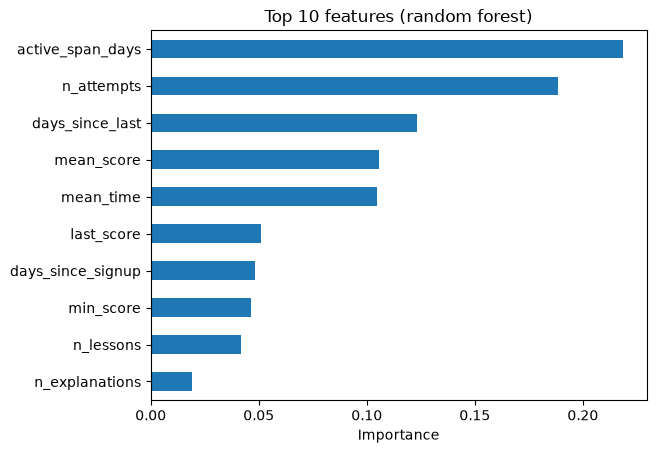

n_explanations       0.019
n_lessons            0.042
min_score            0.046
days_since_signup    0.048
last_score           0.051
mean_time            0.105
mean_score           0.106
days_since_last      0.123
n_attempts           0.188
active_span_days     0.219
dtype: float64

In [5]:
#feature importance
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=X.columns).sort_values()
ax = imp.tail(10).plot(kind="barh")
ax.set_title("Top 10 features (random forest)")
ax.set_xlabel("Importance")
plt.savefig("../outputs/feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
imp.tail(10).round(3)

In [6]:
#leakage check: what happens if refund_requested is added
X2 = X.assign(refund=(df.refund_requested == "yes").astype(int))
Xtr2, Xte2, ytr2, yte2 = train_test_split(X2, y, test_size=0.2, stratify=y, random_state=42)
rf2 = Pipeline([("imp", SimpleImputer(strategy="median")),
                ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                             class_weight="balanced", random_state=42))]).fit(Xtr2, ytr2)
pd.DataFrame([score("random forest (without refund)", yte, rf.predict(Xte)),
              score("random forest + refund (leaky)", yte2, rf2.predict(Xte2))])

,model,precision,recall,f1
0,random forest (without refund),0.65,0.80,0.71
1,random forest + refund (leaky),0.86,0.96,0.91


In [7]:
#threshold trade-off (cross-validated probabilities)
rows = [score(f"threshold {t}", y, (prob >= t).astype(int)) for t in [0.3, 0.4, 0.5, 0.6]]
pd.DataFrame(rows)

,model,precision,recall,f1
0,threshold 0.3,0.50,0.91,0.64
1,threshold 0.4,0.58,0.83,0.68
2,threshold 0.5,0.67,0.77,0.71
3,threshold 0.6,0.74,0.64,0.69


In [8]:
#threshold chosen on the training students only, then checked once on the test set
cv_tr = StratifiedKFold(5, shuffle=True, random_state=42)
prob_tr = cross_val_predict(rf, Xtr, ytr, cv=cv_tr, method="predict_proba")[:, 1]
ok = [t for t in np.arange(0.2, 0.8, 0.05)
      if score("", ytr, (prob_tr >= t).astype(int))["recall"] >= 0.80]
chosen = round(max(ok), 2)
prob_te = rf.predict_proba(Xte)[:, 1]
print("highest threshold with training cross-validated recall of at least 0.80:", chosen)
print("students flagged in the test set at", chosen, ":", int((prob_te >= chosen).sum()), "of", len(yte))
pd.DataFrame([score("test set at 0.5", yte, (prob_te >= 0.5).astype(int)),
              score(f"test set at {chosen} (chosen on training data)", yte, (prob_te >= chosen).astype(int))])

highest threshold with training cross-validated recall of at least 0.80: 0.4
students flagged in the test set at 0.4 : 35 of 100


,model,precision,recall,f1
0,test set at 0.5,0.65,0.8,0.71
1,test set at 0.4 (chosen on training data),0.57,0.8,0.67


The table above picks a threshold by looking at cross-validated predictions for all 500 students, so the 0.83 recall at 0.4 is slightly optimistic: the threshold was chosen on the same data it is reported on. The check here does it properly: the threshold is chosen using the 400 training students only (highest threshold with cross-validated recall of at least 0.80, which is 0.4), and then applied once to the untouched test set. On the test set the recall is 0.80 either way (20 of 25 dropouts caught), and the lower threshold only adds false alarms (precision 0.65 down to 0.57). So 0.4 is a policy choice for a recall-first tool, not a proven gain on this small test set.

In [9]:
#at-risk list for Part 2 (risk scores from cross-validation, threshold 0.4)
THRESH = 0.4
out = df[["student_id"]].assign(risk=prob.round(3))
at_risk = out[out.risk >= THRESH].sort_values("risk", ascending=False)
at_risk.to_csv("../outputs/at_risk_students.csv", index=False)
print(len(at_risk), "students flagged out of", len(df))
at_risk.head()

180 students flagged out of 500


,student_id,risk
322,S323,0.978
150,S151,0.974
77,S078,0.970
481,S482,0.962
243,S244,0.961


## Results and findings

| Model (test set, 100 students) | Precision | Recall | F1 |
|---|---|---|---|
| Always "stays" | 0.00 | 0.00 | 0.00 |
| Rule: inactive > 30 days | 0.32 | 1.00 | 0.48 |
| Logistic regression | 0.65 | 0.80 | 0.71 |
| Random forest | 0.65 | 0.80 | 0.71 |
| Random forest, 5-fold CV (all 500) | 0.67 | 0.77 | 0.71 |

- **Both models clearly beat the baselines.** "Always stays" never flags anyone. The 30-day rule catches every dropout but flags 79% of students, so most flags are false alarms (precision 0.32). The models flag far fewer students and still catch 4 in 5 dropouts.
- **The estimate is stable.** Random forest on the test set: 20 dropouts caught, 5 missed, 11 false alarms, 64 correctly left alone. The 5-fold result agrees with the single split.
- **Activity drives the prediction.** The top features are `active_span_days`, `n_attempts` and `days_since_last`, then scores and time per quiz. Age group, device and country matter little. This matches the EDA: the model mostly learns who has stopped showing up. Importance shows what the model uses, not what causes dropout.
- **Leakage confirmed.** Adding `refund_requested` lifts F1 from 0.71 to 0.91. That is a leak, not a better model, so it stays out.
- **Threshold 0.4** gives recall 0.83 and precision 0.58 in cross-validation, against 0.77 and 0.67 at 0.5. At 0.3 recall reaches 0.91 but half the flags are false alarms. At 0.4, 180 of 500 students (36%) are flagged for Part 2. When the threshold is chosen on the training students only and applied once to the test set, recall is 0.80 at both 0.4 and 0.5 (precision 0.57 vs 0.65), so the benefit of 0.4 is small and noisy with 25 dropouts in the test set.

## Limits and what I would improve
- Small data: 500 students, 125 dropouts, 100 in the test set. Treat F1 0.71 as roughly 0.65 to 0.75.
- Optimistic score: features cover the whole course and there is no dropout date, so part of the signal is the outcome itself (a student who left in July naturally has fewer attempts). With a dropout date I would build features from the first few weeks only, which is how the tool would be used.
- 36% flagged may be more than a team can follow up; the threshold should be set from team capacity.
- The category columns are one-hot encoded with `get_dummies` before the split. No label information is used, so it is not target leakage, but it is not strictly inside the pipeline: a new country or device in production would break it. A `ColumnTransformer` with `OneHotEncoder(handle_unknown="ignore")` in the pipeline would fix this.
- The at-risk list uses out-of-fold risk scores (each student scored by a model that did not train on them) and the threshold 0.4. A deployed version would save one final model and score new students with it.
- Next: tune the model, try gradient boosting, and check that the risk scores are well calibrated.